# Auburn QBs

Auburn-only QB stats from `sql/analysis/Auburn_QBs.sql`.

In [6]:
import os
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# shared project code (src/cfb): paths, database connection, read_query()
from cfb.config import ROOT, SQL_ANALYSIS_DIR
from cfb.db import engine, read_query



In [7]:
query = (SQL_ANALYSIS_DIR / "Auburn_QBs.sql").read_text()

df = pd.read_sql(query, engine)
df

,player,first_season,last_season,seasons,pass_comp,pass_att,pass_pct,pass_yards,pass_tds,pass_ints,rush_att,rush_yards,rush_tds,ppa_total
0,Byrum Brown,2026,2026,1,81.0,125.0,0.648,893.0,6.0,5.0,62.0,237.0,3.0,41.147
1,Tristan Ti'a,2026,2026,1,2.0,4.0,0.500,39.0,0.0,0.0,1.0,0.0,0.0,2.417
2,Will Myers,2026,2026,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Jackson Arnold,2025,2025,1,136.0,215.0,0.633,1309.0,6.0,2.0,112.0,311.0,8.0,53.891
4,Ashton Daniels,2025,2025,1,68.0,119.0,0.571,797.0,3.0,2.0,63.0,280.0,2.0,42.944
5,Deuce Knight,2025,2025,1,17.0,25.0,0.680,259.0,2.0,0.0,13.0,178.0,4.0,17.440
6,Payton Thorne,2023,2024,2,361.0,582.0,0.620,4468.0,37.0,19.0,246.0,798.0,5.0,251.099
7,Hank Brown,2023,2024,2,34.0,52.0,0.654,535.0,6.0,3.0,3.0,10.0,0.0,17.887
8,Holden Geriner,2022,2024,3,9.0,20.0,0.450,116.0,0.0,1.0,5.0,-23.0,0.0,-8.126
9,Walker White,2024,2024,1,2.0,5.0,0.400,18.0,0.0,0.0,4.0,18.0,0.0,-3.606


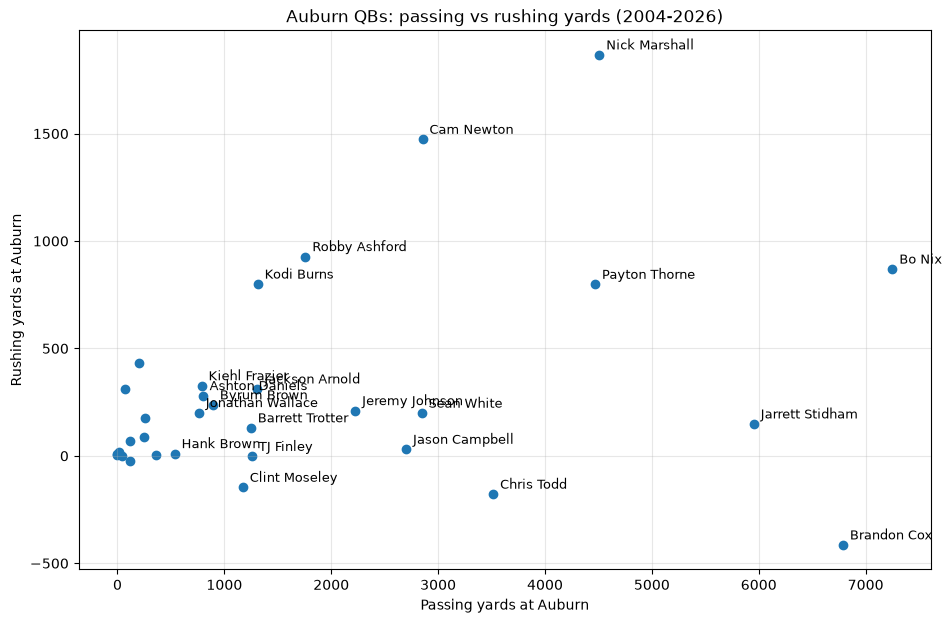

In [13]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(df['pass_yards'], df['rush_yards'])

# label each point with the QB's name; skip QBs with under 50 pass attempts,
# whose labels would pile on top of each other near (0, 0)
for _, row in df[df['pass_att'] >= 50].iterrows():
    ax.annotate(row['player'], (row['pass_yards'], row['rush_yards']),
                xytext=(5, 4), textcoords='offset points', fontsize=9)

ax.set_xlabel('Passing yards at Auburn')
ax.set_ylabel('Rushing yards at Auburn')
ax.set_title('Auburn QBs: passing vs rushing yards (2004-2026)')
ax.grid(alpha=0.3)
plt.show()